<a href="https://colab.research.google.com/github/RiyaSunil28/nitinternship/blob/main/Week3_nit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q open_clip_torch ftfy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00


In [ ]:
import torch
import open_clip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import datasets
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import entropy

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

Using device: cuda


In [ ]:
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

model = model.to(device)
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none')
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ls_2): Identity()
        )
      )
    )
    (ln_post): LayerNorm((768,), eps=1e-05, elementwise_affine

In [ ]:
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=preprocess
)

100%|██████████| 170M/170M [00:13<00:00, 12.3MB/s]


In [ ]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

known_classes = [0, 1, 3, 5, 7]
unknown_classes = [2, 4, 6, 8, 9]

In [ ]:
known_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in known_classes
]

unknown_indices = [
    i for i, (_, label) in enumerate(test_dataset)
    if label in unknown_classes
]

known_set = Subset(test_dataset, known_indices)
unknown_set = Subset(test_dataset, unknown_indices)

print("Known samples:", len(known_set))
print("Unknown samples:", len(unknown_set))

Known samples: 5000
Unknown samples: 5000


In [ ]:
known_loader = DataLoader(
    known_set,
    batch_size=64,
    shuffle=False
)

unknown_loader = DataLoader(
    unknown_set,
    batch_size=64,
    shuffle=False
)

In [ ]:
prompts = [
    f"a photo of a {class_names[i]}"
    for i in known_classes
]

print(prompts)

['a photo of a airplane', 'a photo of a automobile', 'a photo of a cat', 'a photo of a dog', 'a photo of a horse']


In [ ]:
text_tokens = tokenizer(prompts).to(device)

with torch.no_grad():

    text_features = model.encode_text(text_tokens)

    text_features = text_features / text_features.norm(
        dim=-1,
        keepdim=True
    )

In [ ]:
images, _ = next(iter(known_loader))

images = images.to(device)

with torch.no_grad():

    image_features = model.encode_image(images)

    image_features = image_features / image_features.norm(
        dim=-1,
        keepdim=True
    )

    similarity = image_features @ text_features.T

print(similarity.shape)

torch.Size([64, 5])


In [ ]:
def get_clip_scores(loader):

    max_similarity = []
    entropy_scores = []

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(device)

            image_features = model.encode_image(images)

            image_features = image_features / image_features.norm(
                dim=-1,
                keepdim=True
            )

            similarity = image_features @ text_features.T

            probabilities = torch.softmax(
                similarity,
                dim=1
            )

            max_scores = similarity.max(
                dim=1
            ).values

            ent = entropy(
                probabilities.cpu().numpy(),
                axis=1
            )

            max_similarity.extend(
                max_scores.cpu().numpy()
            )

            entropy_scores.extend(ent)

    return (
        np.array(max_similarity),
        np.array(entropy_scores)
    )

In [ ]:
known_similarity, known_entropy = get_clip_scores(
    known_loader
)

unknown_similarity, unknown_entropy = get_clip_scores(
    unknown_loader
)

In [ ]:
labels = np.concatenate([
    np.ones(len(known_similarity)),
    np.zeros(len(unknown_similarity))
])

In [ ]:
similarity_scores = np.concatenate([
    known_similarity,
    unknown_similarity
])

entropy_scores = -np.concatenate([
    known_entropy,
    unknown_entropy
])

similarity_auroc = roc_auc_score(
    labels,
    similarity_scores
)

entropy_auroc = roc_auc_score(
    labels,
    entropy_scores
)

print(f"Similarity AUROC: {similarity_auroc:.4f}")
print(f"Entropy AUROC: {entropy_auroc:.4f}")

Similarity AUROC: 0.9153
Entropy AUROC: 0.9205


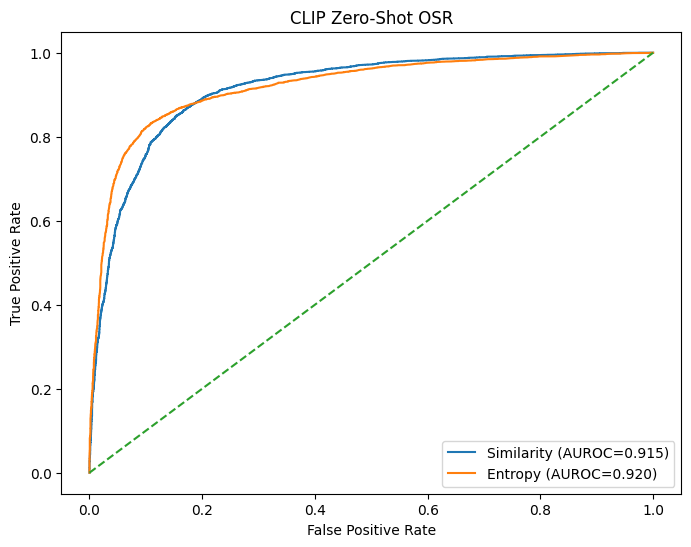

In [ ]:
sim_fpr, sim_tpr, _ = roc_curve(
    labels,
    similarity_scores
)

ent_fpr, ent_tpr, _ = roc_curve(
    labels,
    entropy_scores
)

plt.figure(figsize=(8, 6))

plt.plot(
    sim_fpr,
    sim_tpr,
    label=f"Similarity (AUROC={similarity_auroc:.3f})"
)

plt.plot(
    ent_fpr,
    ent_tpr,
    label=f"Entropy (AUROC={entropy_auroc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("CLIP Zero-Shot OSR")

plt.legend()

plt.show()

In [ ]:
results = pd.DataFrame({

    "Method": [
        "Max Similarity",
        "Entropy"
    ],

    "AUROC": [
        round(similarity_auroc, 4),
        round(entropy_auroc, 4)
    ]
})

results

,Method,AUROC
0,Max Similarity,0.9153
1,Entropy,0.9205


In [ ]:
vit_msp = 0.4172
vit_energy = 0.3922

In [ ]:
comparison = pd.DataFrame({

    "Method": [
        "ViT + MSP",
        "ViT + Energy",
        "CLIP + Similarity",
        "CLIP + Entropy"
    ],

    "AUROC": [
        vit_msp,
        vit_energy,
        round(similarity_auroc, 4),
        round(entropy_auroc, 4)
    ]
})

comparison

,Method,AUROC
0,ViT + MSP,0.4172
1,ViT + Energy,0.3922
2,CLIP + Similarity,0.9153
3,CLIP + Entropy,0.9205
